In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(r"C:\Users\dkart\Downloads\archive\olist_order_items_dataset.csv")

print(df.head())
print(df.shape)
print(df.info())

                           order_id  order_item_id  \
0  00010242fe8c5a6d1ba2dd792cb16214              1   
1  00018f77f2f0320c557190d7a144bdd3              1   
2  000229ec398224ef6ca0657da4fc703e              1   
3  00024acbcdf0a6daa1e931b038114c75              1   
4  00042b26cf59d7ce69dfabb4e55b4fd9              1   

                         product_id                         seller_id  \
0  4244733e06e7ecb4970a6e2683c13e61  48436dade18ac8b2bce089ec2a041202   
1  e5f2d52b802189ee658865ca93d83a8f  dd7ddc04e1b6c2c614352b383efe2d36   
2  c777355d18b72b67abbeef9df44fd0fd  5b51032eddd242adc84c38acab88f23d   
3  7634da152a4610f1595efa32f14722fc  9d7a1d34a5052409006425275ba1c2b4   
4  ac6c3623068f30de03045865e4e10089  df560393f3a51e74553ab94004ba5c87   

   shipping_limit_date   price  freight_value  
0  2017-09-19 09:45:35   58.90          13.29  
1  2017-05-03 11:05:13  239.90          19.93  
2  2018-01-18 14:48:30  199.00          17.87  
3  2018-08-15 10:10:18   12.99          12.7

In [2]:
# Select numerical columns
numeric_df = df.select_dtypes(include=np.number)

# Descriptive statistics
print(numeric_df.describe())

# Individual statistical measures
print("Mean:\n", numeric_df.mean())
print("Median:\n", numeric_df.median())
print("Mode:\n", numeric_df.mode().iloc[0])
print("Variance:\n", numeric_df.var())
print("Standard Deviation:\n", numeric_df.std())

       order_item_id          price  freight_value
count  112650.000000  112650.000000  112650.000000
mean        1.197834     120.653739      19.990320
std         0.705124     183.633928      15.806405
min         1.000000       0.850000       0.000000
25%         1.000000      39.900000      13.080000
50%         1.000000      74.990000      16.260000
75%         1.000000     134.900000      21.150000
max        21.000000    6735.000000     409.680000
Mean:
 order_item_id      1.197834
price            120.653739
freight_value     19.990320
dtype: float64
Median:
 order_item_id     1.00
price            74.99
freight_value    16.26
dtype: float64
Mode:
 order_item_id     1.0
price            59.9
freight_value    15.1
Name: 0, dtype: float64
Variance:
 order_item_id        0.497200
price            33721.419531
freight_value      249.842452
dtype: float64
Standard Deviation:
 order_item_id      0.705124
price            183.633928
freight_value     15.806405
dtype: float64


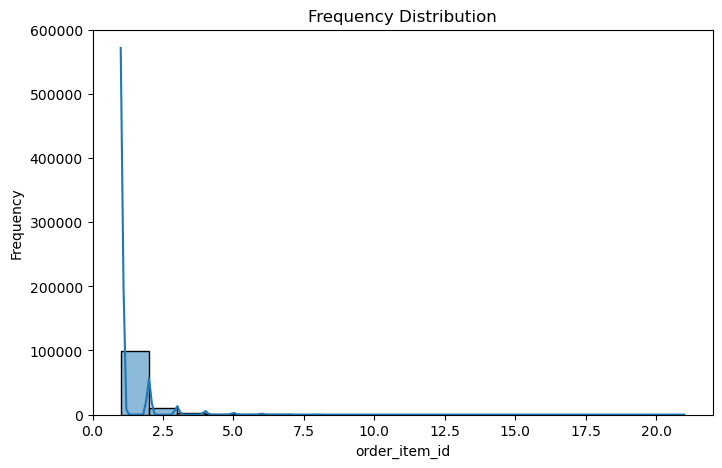

In [3]:
column = numeric_df.columns[0]

plt.figure(figsize=(8, 5))
sns.histplot(df[column].dropna(), bins=20, kde=True)

plt.title("Frequency Distribution")
plt.xlabel(column)
plt.ylabel("Frequency")

plt.show()

In [4]:
print("25th Percentile:", numeric_df.quantile(0.25))
print("50th Percentile:", numeric_df.quantile(0.50))
print("75th Percentile:", numeric_df.quantile(0.75))

Q1 = numeric_df.quantile(0.25)
Q3 = numeric_df.quantile(0.75)

IQR = Q3 - Q1

print("IQR:\n", IQR)

25th Percentile: order_item_id     1.00
price            39.90
freight_value    13.08
Name: 0.25, dtype: float64
50th Percentile: order_item_id     1.00
price            74.99
freight_value    16.26
Name: 0.5, dtype: float64
75th Percentile: order_item_id      1.00
price            134.90
freight_value     21.15
Name: 0.75, dtype: float64
IQR:
 order_item_id     0.00
price            95.00
freight_value     8.07
dtype: float64


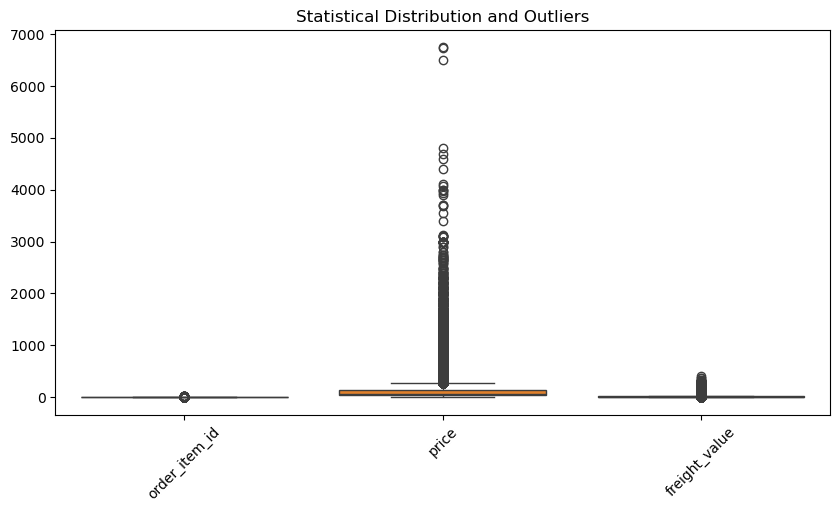

In [5]:
plt.figure(figsize=(10, 5))

sns.boxplot(data=numeric_df)

plt.title("Statistical Distribution and Outliers")
plt.xticks(rotation=45)

plt.show()

In [6]:
numeric_df.describe().to_csv("statistics_summary.csv")